# LAB3 - Bài 5 (Trang 26): Gom cụm MNIST bằng k-Means và so sánh với nhãn lớp có sẵn
**Đinh Nhật Huyền Nhân - 6451071055 - CQ.64.CNTT**

In [1]:
print("Đinh Nhật Huyền Nhân - 6451071055")
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.datasets import mnist
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score)

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
X_train = train_images.reshape(len(train_images), -1) / 255.0   # 60000 x 784, giá trị [0,1]
X_test = test_images.reshape(len(test_images), -1) / 255.0
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Số mẫu mỗi nhãn (train):", np.bincount(train_labels))

Đinh Nhật Huyền Nhân - 6451071055


X_train: (60000, 784) | X_test: (10000, 784)
Số mẫu mỗi nhãn (train): [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [2]:
print("Đinh Nhật Huyền Nhân - 6451071055")
kmeans = KMeans(n_clusters=10, init="k-means++", n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_train)
print("Inertia (WSS):", round(kmeans.inertia_, 2))
print("Số mẫu mỗi cụm:", np.bincount(clusters))

Đinh Nhật Huyền Nhân - 6451071055


Inertia (WSS): 2352826.63
Số mẫu mỗi cụm: [5720 5966 6526 4679 3178 5592 8855 8934 7454 3096]


Đinh Nhật Huyền Nhân - 6451071055


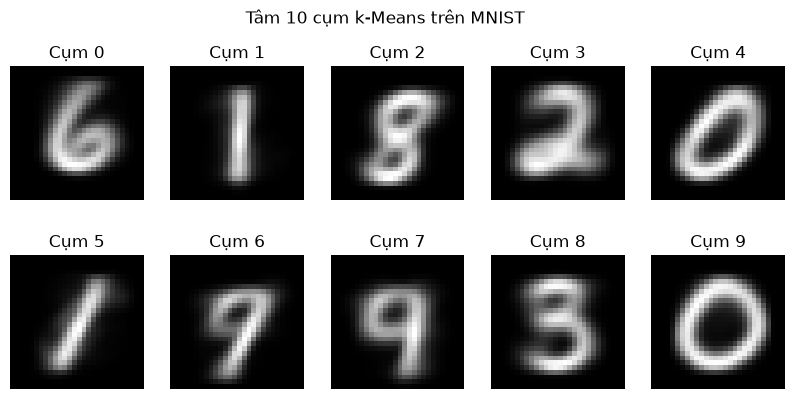

In [3]:
print("Đinh Nhật Huyền Nhân - 6451071055")
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(kmeans.cluster_centers_[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Cụm {i}"); ax.axis("off")
plt.suptitle("Tâm 10 cụm k-Means trên MNIST"); plt.show()

Đinh Nhật Huyền Nhân - 6451071055


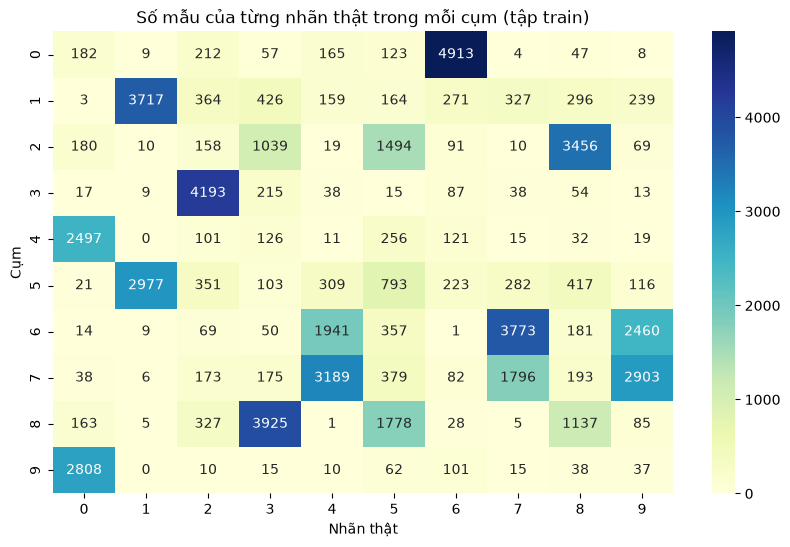

Ánh xạ cụm -> nhãn: {0: 6, 1: 1, 2: 8, 3: 2, 4: 0, 5: 1, 6: 7, 7: 4, 8: 3, 9: 0}
Các chữ số không là nhãn đa số của cụm nào: [5, 9]


In [4]:
print("Đinh Nhật Huyền Nhân - 6451071055")
bang_cheo = pd.crosstab(clusters, train_labels, rownames=["Cụm"], colnames=["Nhãn thật"])
plt.figure(figsize=(10, 6))
sns.heatmap(bang_cheo, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Số mẫu của từng nhãn thật trong mỗi cụm (tập train)"); plt.show()

# Gán cho mỗi cụm nhãn xuất hiện nhiều nhất trong cụm đó
cum_sang_nhan = {c: int(bang_cheo.loc[c].idxmax()) for c in bang_cheo.index}
print("Ánh xạ cụm -> nhãn:", cum_sang_nhan)
print("Các chữ số không là nhãn đa số của cụm nào:", sorted(set(range(10)) - set(cum_sang_nhan.values())))

In [5]:
print("Đinh Nhật Huyền Nhân - 6451071055")
y_pred_train = np.array([cum_sang_nhan[c] for c in clusters])
print("Accuracy (train, sau ánh xạ cụm -> nhãn):", round(accuracy_score(train_labels, y_pred_train), 4))
print("Adjusted Rand Index :", round(adjusted_rand_score(train_labels, clusters), 4))
print("NMI                 :", round(normalized_mutual_info_score(train_labels, clusters), 4))
print("Homogeneity         :", round(homogeneity_score(train_labels, clusters), 4))
print("Completeness        :", round(completeness_score(train_labels, clusters), 4))
print()
print(classification_report(train_labels, y_pred_train, digits=4, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy (train, sau ánh xạ cụm -> nhãn): 0.5908
Adjusted Rand Index : 0.3607
NMI                 : 0.4906
Homogeneity         : 0.485
Completeness        : 0.4964

              precision    recall  f1-score   support

           0     0.8456    0.8957    0.8699      5923
           1     0.5792    0.9929    0.7316      6742
           2     0.8961    0.7038    0.7884      5958
           3     0.5266    0.6402    0.5778      6131
           4     0.3570    0.5459    0.4316      5842
           5     0.0000    0.0000    0.0000      5421
           6     0.8589    0.8302    0.8443      5918
           7     0.4261    0.6022    0.4991      6265
           8     0.5296    0.5907    0.5585      5851
           9     0.0000    0.0000    0.0000      5949

    accuracy                         0.5908     60000
   macro avg     0.5019    0.5801    0.5301     60000
weighted avg     0.5069    0.5908    0.5373     60000



Đinh Nhật Huyền Nhân - 6451071055
Accuracy trên tập test: 0.595


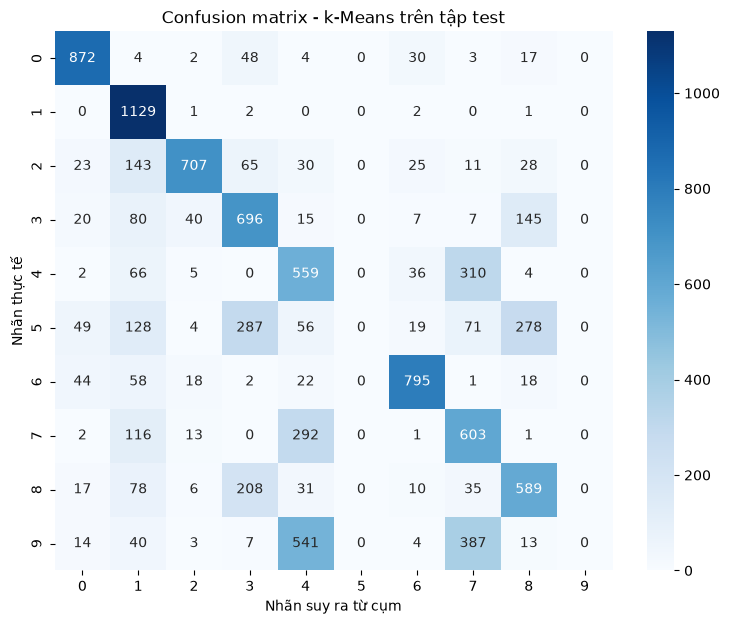

In [6]:
print("Đinh Nhật Huyền Nhân - 6451071055")
y_pred_test = np.array([cum_sang_nhan[c] for c in kmeans.predict(X_test)])
print("Accuracy trên tập test:", round(accuracy_score(test_labels, y_pred_test), 4))
cm = confusion_matrix(test_labels, y_pred_test, labels=range(10))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Nhãn suy ra từ cụm"); plt.ylabel("Nhãn thực tế"); plt.title("Confusion matrix - k-Means trên tập test")
plt.show()

- k-Means (k=10) gom 60.000 ảnh MNIST mà không dùng nhãn. Sau khi gán cho mỗi cụm nhãn chiếm đa số trong cụm đó, độ chính xác đạt khoảng 0.59 trên tập train và 0.595 trên tập test; ARI ≈ 0.36, NMI ≈ 0.49.
- Các chữ số có nét viết đặc trưng (0, 2, 6) tạo thành cụm khá thuần. Chữ số 1 có recall gần 1 nhưng precision chỉ ≈ 0.58, vì hai cụm được gán nhãn 1 chứa lẫn nhiều chữ số khác (nét mảnh, nghiêng). Các chữ số có hình dạng gần nhau bị gộp chung: 4-7-9 rơi vào cùng cụm, 3-5-8 trộn lẫn. Vì vậy hai chữ số 5 và 9 không là nhãn đa số của cụm nào, còn chữ số 0 và 1 chiếm tới 2 cụm.
- Lý do: k-Means dùng khoảng cách Euclide trên các điểm ảnh thô, nên một chữ số viết theo nhiều kiểu (ví dụ số 1 thẳng và số 1 nghiêng) có thể bị tách thành nhiều cụm, còn các chữ số khác nhau nhưng có nhiều điểm ảnh trùng nhau lại bị gộp chung.
- So với Neural Network có giám sát ở Bài 2 và Bài 3 (accuracy ≈ 0.97), gom cụm kém hơn nhiều. Tuy vậy k-Means vẫn tìm ra được cấu trúc có ý nghĩa mà không cần nhãn: tâm cụm hiển thị như những chữ số "trung bình".